In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/python_packages")
from myutils.composite_functions import select_events, var_composites

## Parameters

In [2]:
timesfut = ["2070-01", "2100-01"]
timespi  = ["1850-01", "1880-01"]

n3     = [-5, 5, 210, 270]
n34    = [-5, 5, 190, 240]
n4    = [-5, 5, 160, 210]
regbox = [-40, 40, 90, 300]

# Seasonal windows (months relative to DJF peak)
SEASONS = {
    'JJA': (-7, -5),   # ~6 months before
    'SON': (-4, -1),   # ~3 months before
}

var_names = [
    "Qp", "ekU", "ekV", "eddyU", "eddyV",
    "UmdTpdx", "VmdTpdy", "upwelling", "eddyvert",
    "thermocline", "dTpdt"
]

#less_vars = [
#    "Qp", "zonal Ekman", "meridional Ekman", "eddyU", "eddyV",
#    "upwelling", "eddyvert", "thermocline", "dTpdt"
#]
less_vars = [
    "Q'", "zonal Ekman", "meridional Ekman", "eddyU", "eddyV",
    "upwelling", "eddyvert", "thermocline",
    r'$\frac{\partial T\prime}{\partial t}$'
]

In [3]:
labels=less_vars = [
    "Q'", "zonal Ekman", "meridional Ekman", "eddyU", "eddyV",
    "upwelling", "eddyW", "thermocline",
    r'$\frac{\partial T\prime}{\partial t}$'
]

## Load data

In [4]:
dssst    = xr.open_dataset("/glade/work/smagahey/UCSB/codes/generated_files/tos_1850_2100_E3SMv1LE.nc")
tosd     = dssst['tos']
tos      = tosd - tosd.mean('member')

ds_hb_fut  = xr.open_dataset("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/hb_analysis/fut_corrQ_hb_terms.nc")
ds_hb_hist = xr.open_dataset("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/hb_analysis/hist_corrQ_hb_terms.nc")
reg=n34
vars_hist = {var: ds_hb_hist[var].sel(lon=slice(reg[2], reg[3])) for var in var_names}
vars_fut  = {var: ds_hb_fut[var].sel(lon=slice(reg[2],  reg[3])) for var in var_names}

yrshist = xr.DataArray(np.arange(1850, 1880).astype(str), dims='time')
yrsfut  = xr.DataArray(np.arange(2070, 2100).astype(str), dims='time')

# Identify events
enyrs_h, lnyrs_h = select_events(tos, n34, regbox, 1850, 1880, timespi)
enyrs_f, lnyrs_f = select_events(tos, n34, regbox, 2070, 2100, timesfut)

# Limit to 14 members
enyrs_h = enyrs_h.isel(member=slice(0, 14))
enyrs_f = enyrs_f.isel(member=slice(0, 14))
lnyrs_h = lnyrs_h.isel(member=slice(0, 14))
lnyrs_f = lnyrs_f.isel(member=slice(0, 14))

## Compute composites for JJA and SON windows

In [5]:
def compute_area_mean(composite, m1, m2):
    """Area-average composite over Nino3 region and time window."""
    return (composite
            .sel(lat=slice(-5, 5), lon=slice(190,240), time=slice(m1, m2))
            .mean('member').mean('time').mean('lat').mean('lon'))


def combine_terms(vals):
    """
    Combine ekU+UmdTpdx and ekV+VmdTpdy, return less_vars list.
    vals is indexed by var_names order.
    """
    tot_ekU = vals[1]    # ekU + UmdTpdx + vals[5]
    tot_ekV = vals[2]    # ekV + VmdTpdy + vals[6]
    return [vals[0], tot_ekU, tot_ekV, vals[3], vals[4],
            vals[7], vals[8], vals[9], vals[10]]


# Storage: results[season][period][en/ln] = list of term values
results = {}

for season, (m1, m2) in SEASONS.items():
    print(f'Computing {season} (months {m1} to {m2})...')
    results[season] = {}

    # PI composites
    nino_pi_raw, nina_pi_raw = [], []
    for varn in var_names:
        comp_en, comp_ln = var_composites(
            vars_hist[varn].isel(member=slice(0, 14)),
            yrshist, enyrs_h, lnyrs_h, 24
        )
        nino_pi_raw.append(compute_area_mean(comp_en, m1, m2))
        nina_pi_raw.append(compute_area_mean(comp_ln, m1, m2))

    # Future composites
    nino_fut_raw, nina_fut_raw = [], []
    for varn in var_names:
        comp_en, comp_ln = var_composites(
            vars_fut[varn].isel(member=slice(0, 14)),
            yrsfut, enyrs_f, lnyrs_f, 24
        )
        nino_fut_raw.append(compute_area_mean(comp_en, m1, m2))
        nina_fut_raw.append(compute_area_mean(comp_ln, m1, m2))

    results[season]['pi_ln']  = combine_terms(nina_pi_raw)
    results[season]['fut_ln'] = combine_terms(nina_fut_raw)
    results[season]['pi_en']  = combine_terms(nino_pi_raw)
    results[season]['fut_en'] = combine_terms(nino_fut_raw)

print('Done.')

Computing JJA (months -7 to -5)...
Computing SON (months -4 to -1)...
Done.


## Plot: 2-panel JJA and SON

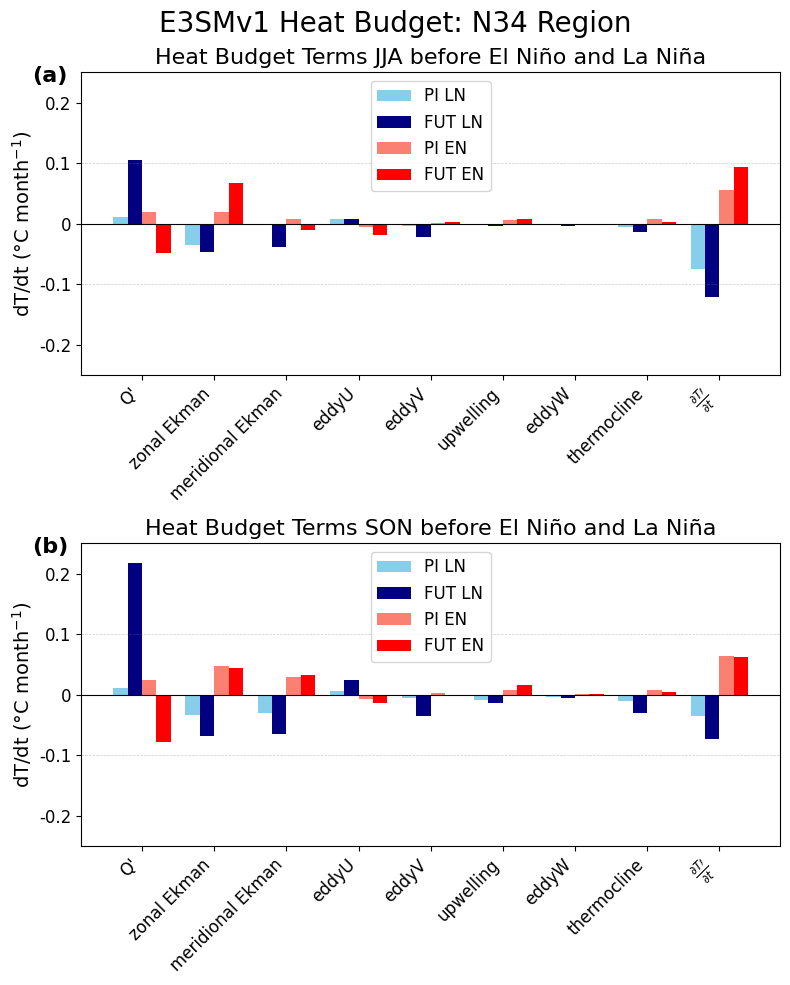

In [6]:
x     = np.arange(len(less_vars))
width = 0.2

fig, axes = plt.subplots(2, 1, figsize=(8,10))

season_titles = {
    'JJA': 'JJA before El Niño and La Niña',
    'SON': 'SON before El Niño and La Niña',
}

for ax, season in zip(axes, ['JJA', 'SON']):
    r = results[season]

    ax.bar(x - 1.5*width, r['pi_ln'],  width, label='PI LN',  color='skyblue')
    ax.bar(x - 0.5*width, r['fut_ln'], width, label='FUT LN', color='navy')
    ax.bar(x + 0.5*width, r['pi_en'],  width, label='PI EN',  color='salmon')
    ax.bar(x + 1.5*width, r['fut_en'], width, label='FUT EN', color='red')

    ax.axhline(0,    color='k',    lw=0.8)
    ax.axhline( 0.1, color='gray', lw=0.5, ls='--', alpha=0.4)
    ax.axhline(-0.1, color='gray', lw=0.5, ls='--', alpha=0.4)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha='right',fontsize=12)
    ax.set_yticks([-.2,-.1,0,.1,.2])
    ax.set_yticklabels(['-0.2','-0.1','0','0.1','0.2'],fontsize=12)
    ax.set_ylabel('dT/dt (°C month$^{-1}$)',fontsize=14)
    ax.set_title(f'Heat Budget Terms {season_titles[season]}', fontsize=16)
    ax.legend(fontsize=12,loc='upper center')
    ax.set_ylim(-0.25, 0.25)
for ax, label in zip(axes, ['(a)', '(b)']):
    ax.text(-0.07, 1.02, label, transform=ax.transAxes,
            fontsize=16, fontweight='bold', va='top', ha='left')
fig.suptitle('E3SMv1 Heat Budget: N34 Region', fontsize=20)
plt.tight_layout()
plt.savefig('heatbudget_barplot_jja_son_n34.png', dpi=150, bbox_inches='tight')
plt.show()